## TarNet method verification

### Generate data

In [ ]:
import numpy as np
import statsmodels.api as sm
import re
#np.random.seed(42)
#### Generate linear data
def generate_linear_datazz(n, N_x, B):
    #generate treatment, N_x == p
    # B = Beta1
##generate Cov
    # Generate a random correlation matrix within the interval (-0.4, +0.4)
    random_corr_matrix = np.random.uniform(low=-0.4, high=0.4, size=(N_x, N_x))
    # Make the matrix symmetric to ensure it's a valid correlation matrix
    random_corr_matrix = (random_corr_matrix + random_corr_matrix.T) / 2
    # Set the diagonal to 1 for a valid correlation matrix
    np.fill_diagonal(random_corr_matrix, 1)
    # Check if the correlation matrix is positive semi-definite
    # If not, make small adjustments to ensure it is
    eigenvalues, eigenvectors = np.linalg.eigh(random_corr_matrix)
    if np.any(eigenvalues < 0):
        eigenvalues = np.clip(eigenvalues, a_min=0, a_max=None)
        random_corr_matrix = eigenvectors @ np.diag(eigenvalues) @ eigenvectors.T
    # Assume unit variances for simplicity, making the covariance matrix equal to the correlation matrix
    covariance_matrix = random_corr_matrix
    # Mean vector for the multivariate normal distribution
    mean_vector = np.zeros(N_x)
    # Generate the COV matrix from the multivariate normal distribution.
    Cov = np.random.multivariate_normal(mean=mean_vector, cov=covariance_matrix, size=n)


    delta = np.full((N_x, 1), 0.6)
    gamma = np.full((N_x, 1), 0.6)
    epsilon_y = np.random.normal(0, 1, size = (n,1))


# Generate epsilon_t from a normal distribution with mean 0 and variance 1, because COV is randomly generated by ramdom covariance matrix, it is very hard to control the variance of T* always equal to 1.
    epsilon_t = np.random.normal(loc=0, scale=1, size=(n, 1))
# Compute the latent treatment
    latent_treatment = Cov @ gamma + epsilon_t
    treatment = np.where(latent_treatment<0, 0, 1)


##generate Y
    Y = treatment * B + Cov @ delta + epsilon_y
    return Cov, treatment, Y

In [ ]:
import numpy as np

def generate_linear_data(n, N_x, B):
    """
    Generate linear data with interaction effects between covariates.

    Parameters:
    - n: Number of samples.
    - N_x: Number of covariates.
    - B: Treatment effect coefficient.

    Returns:
    - Cov: Covariate matrix (n x N_x).
    - treatment: Treatment assignment (n x 1).
    - Y: Outcome variable (n x 1).
    """
    # Generate a random correlation matrix within the interval (-0.4, +0.4)
    random_corr_matrix = np.random.uniform(low=-0.4, high=0.4, size=(N_x, N_x))
    random_corr_matrix = (random_corr_matrix + random_corr_matrix.T) / 2
    np.fill_diagonal(random_corr_matrix, 1)

    # Ensure the correlation matrix is positive semi-definite
    eigenvalues, eigenvectors = np.linalg.eigh(random_corr_matrix)
    if np.any(eigenvalues < 0):
        eigenvalues = np.clip(eigenvalues, a_min=0, a_max=None)
        random_corr_matrix = eigenvectors @ np.diag(eigenvalues) @ eigenvectors.T

    covariance_matrix = random_corr_matrix
    mean_vector = np.zeros(N_x)

    # Generate covariates from a multivariate normal distribution
    Cov = np.random.multivariate_normal(mean=mean_vector, cov=covariance_matrix, size=n)

    # Coefficients for main effects
    delta = np.full((N_x, 1), 0.6)
    gamma = np.full((N_x, 1), 0.6)

    # Generate noise
    epsilon_y = np.random.normal(0, 1, size=(n, 1))
    epsilon_t = np.random.normal(0, 1, size=(n, 1))

    # Compute latent treatment and binary treatment assignment
    latent_treatment = Cov @ gamma + epsilon_t
    treatment = np.where(latent_treatment < 0, 0, 1)

    # Compute interaction effects
    interaction_effects = np.zeros((n, 1))
    for i in range(N_x):
        for j in range(i + 1, N_x):
            interaction_effects += Cov[:, i].reshape(-1, 1) * Cov[:, j].reshape(-1, 1)

    # Coefficient for interaction effects
    interaction_coeff =0.1

    # Generate outcome variable
    Y = treatment * B + Cov @ delta + interaction_coeff * interaction_effects*5 + epsilon_y

    return Cov, treatment, Y


In [ ]:
# All linear data :For n = 500. (N_x=2, "treatment effect" beta = B = 0 /0.5)
#same as X_500_2_0 for example in the thesis, the nonlinear generated data was omitted.
X_500_2_0_l, treatment_500_2_0_l, Y_500_2_0_l = generate_linear_data(500, 2, 0.0)
X_500_2_05_l, treatment_500_2_05_l, Y_500_2_05_l = generate_linear_data(500, 2, 5)
X_500_25_0_l, treatment_500_25_0_l, Y_500_25_0_l = generate_linear_data(500, 25, 0.0)
X_500_25_05_l, treatment_500_25_05_l, Y_500_25_05_l = generate_linear_data(500, 25, 5)
X_500_50_0_l, treatment_500_50_0_l, Y_500_50_0_l = generate_linear_data(500, 50, 0.0)
X_500_50_05_l, treatment_500_50_05_l, Y_500_50_05_l = generate_linear_data(500, 50, 5)

# All linear data :For n = 1000.
X_1000_2_0_l, treatment_1000_2_0_l, Y_1000_2_0_l = generate_linear_data(1000, 2, 0.0)
X_1000_2_05_l, treatment_1000_2_05_l, Y_1000_2_05_l = generate_linear_data(1000, 2, 5)
X_1000_25_0_l, treatment_1000_25_0_l, Y_1000_25_0_l = generate_linear_data(1000, 25, 0.0)
X_1000_25_05_l, treatment_1000_25_05_l, Y_1000_25_05_l = generate_linear_data(1000, 25, 5)
X_1000_50_0_l, treatment_1000_50_0_l, Y_1000_50_0_l = generate_linear_data(1000, 50, 0.0)
X_1000_50_05_l, treatment_1000_50_05_l, Y_1000_50_05_l = generate_linear_data(1000, 50, 5)

## X==COV

In [ ]:
###Check the number of treatment groups and control groups, should be unbalanced!
# Calculate the number of 0s and 1s
num_zeros = np.sum(treatment_500_25_05_l == 0)
num_ones = np.sum(treatment_1000_25_05_l == 1)

In [ ]:
num_ones

473

In [ ]:
num_zeros

269

In [ ]:
X_1000_2_0_l

array([[ 1.62133583,  1.59568013],
       [ 0.38962029, -0.85113183],
       [ 1.76505847,  0.96513173],
       ...,
       [ 0.54223316, -0.52610624],
       [-0.52895744, -0.59449   ],
       [ 1.49777473, -1.65685808]])

In [ ]:
X_500_2_0_l

array([[-3.26373699e-01, -7.90219874e-02],
       [ 1.04300164e+00, -3.68576482e-01],
       [-8.15237896e-01,  3.17084949e-01],
       [-2.38578900e+00,  2.07317854e-01],
       [-2.86318782e-01, -1.72035576e+00],
       [ 9.78526642e-01, -6.60768547e-02],
       [-6.43247077e-01,  1.25361590e+00],
       [ 5.76343255e-01,  3.05187857e+00],
       [-2.30427396e+00, -9.21948884e-01],
       [ 1.11979192e+00,  2.11506387e-01],
       [ 5.88710506e-01,  1.97326554e+00],
       [ 5.98873305e-02, -3.59831525e-01],
       [ 1.01748054e-01, -3.57008948e-01],
       [-9.01785826e-01, -1.53573078e+00],
       [-1.32290094e+00,  5.34138038e-01],
       [-2.21941583e-01, -1.20444731e+00],
       [ 8.25759538e-02, -9.98481727e-01],
       [ 7.18699853e-01,  5.23981312e-01],
       [-1.08561252e+00,  1.93043448e-02],
       [-1.31194430e+00,  4.58394306e-01],
       [ 1.09234308e+00,  8.64781373e-01],
       [-6.38184062e-01, -2.22868716e-01],
       [-1.80175762e-01,  4.07831757e-01],
       [ 7.

In [ ]:
print(Y_1000_50_05_l.shape)
print(X_1000_50_05_l.shape)
print(treatment_1000_50_05_l.shape)

(1000, 1)
(1000, 50)
(1000, 1)


## TarNet Estimation

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.losses import Loss
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, TensorBoard, ReduceLROnPlateau, TerminateOnNaN
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback
import datetime
import statsmodels.api as sm
import re


In [ ]:
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

def OLS_RMSE(Y, X, T):
    X = sm.add_constant(X)
    # Stack T to X matrix, so the first coefficient is B hat.
    XT = np.concatenate((X, T), axis=1)
    model = sm.OLS(Y, XT)
    results = model.fit()

    # Predict using the model
    Y_pred = results.predict(XT)

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(Y, Y_pred))
    return rmse



In [ ]:
# every loss function in TF2 takes 2 arguments, a vector of true values and a vector predictions
def regression_loss(concat_true, concat_pred):
    #computes a standard MSE loss for TARNet
    y_true = concat_true[:, 0] #get individual vectors
    t_true = concat_true[:, 1]

    y0_pred = concat_pred[:, 0]
    y1_pred = concat_pred[:, 1]

    #Each head outputs a prediction for both potential outcomes
    #We use t_true as a switch to only calculate the factual loss
    loss0 = tf.reduce_sum((1. - t_true) * tf.square(y_true - y0_pred))
    loss1 = tf.reduce_sum(t_true * tf.square(y_true - y1_pred))
    #note Shi uses tf.reduce_sum for her losses even though mathematically we should be using the mean
    #tf.reduce_mean and tf.reduce_sum should be equivalent, but maybe having larger error gradients makes training easier?
    return loss0 + loss1


In [ ]:
# Define the custom loss function (as provided in "Tarnet basic (1).ipynb" notebook)
def pdist2sq(x,y):
    x2 = tf.reduce_sum(x ** 2, axis=-1, keepdims=True)
    y2 = tf.reduce_sum(y ** 2, axis=-1, keepdims=True)
    dist = x2 + tf.transpose(y2, (1, 0)) - 2. * x @ tf.transpose(y, (1, 0))
    return dist


class CFRNet_Loss(Loss):
  #initialize instance attributes
  def __init__(self, alpha=1.,sigma=1.):
      super().__init__()
      self.alpha = alpha # balances regression loss and MMD IPM
      self.rbf_sigma=sigma #for gaussian kernel
      self.name='cfrnet_loss'

  def split_pred(self,concat_pred):
      #generic helper to make sure we dont make mistakes
      preds={}
      preds['y0_pred'] = concat_pred[:, 0]
      preds['y1_pred'] = concat_pred[:, 1]
      preds['phi'] = concat_pred[:, 2:]
      return preds

  def rbf_kernel(self, x, y):
    return tf.exp(-pdist2sq(x,y)/tf.square(self.rbf_sigma))

  def calc_mmdsq(self, Phi, t):
    Phic, Phit =tf.dynamic_partition(Phi,tf.cast(tf.squeeze(t),tf.int32),2)

    Kcc = self.rbf_kernel(Phic,Phic)
    Kct = self.rbf_kernel(Phic,Phit)
    Ktt = self.rbf_kernel(Phit,Phit)

    m = tf.cast(tf.shape(Phic)[0],Phi.dtype)
    n = tf.cast(tf.shape(Phit)[0],Phi.dtype)

    mmd = 1.0/(m*(m-1.0))*(tf.reduce_sum(Kcc))
    mmd = mmd + 1.0/(n*(n-1.0))*(tf.reduce_sum(Ktt))
    mmd = mmd - 2.0/(m*n)*tf.reduce_sum(Kct)
    return mmd * tf.ones_like(t)

  def mmdsq_loss(self, concat_true,concat_pred):
    t_true = concat_true[:, 1]
    p=self.split_pred(concat_pred)
    mmdsq_loss = tf.reduce_mean(self.calc_mmdsq(p['phi'],t_true))
    return mmdsq_loss

  def regression_loss(self,concat_true,concat_pred):
      y_true = concat_true[:, 0]
      t_true = concat_true[:, 1]
      p = self.split_pred(concat_pred)
      loss0 = tf.reduce_mean((1. - t_true) * tf.square(y_true - p['y0_pred']))
      loss1 = tf.reduce_mean(t_true * tf.square(y_true - p['y1_pred']))
      return loss0+loss1

  def cfr_loss(self,concat_true,concat_pred):

      lossR = self.regression_loss(concat_true,concat_pred)
      lossIPM = self.mmdsq_loss(concat_true,concat_pred)
      return lossR + self.alpha *lossIPM

  #compute loss
  def call(self, concat_true, concat_pred):
      return self.cfr_loss(concat_true,concat_pred)




In [ ]:
import tensorflow as tf
from tensorflow.keras.callbacks import Callback

class Base_Metrics(Callback):
    def __init__(self, data, verbose=0):
        super(Base_Metrics, self).__init__()
        self.data = data
        self.verbose = verbose
        self.data['o_idx'] = tf.range(self.data['t'].shape[0])
        self.data['c_idx'] = self.data['o_idx'][tf.squeeze(self.data['t']) == 0]
        self.data['t_idx'] = self.data['o_idx'][tf.squeeze(self.data['t']) == 1]

    def split_pred(self, concat_pred):
        preds = {}
        y0_pred_scaled = tf.reshape(concat_pred[:, 0], [-1, 1])
        y1_pred_scaled = tf.reshape(concat_pred[:, 1], [-1, 1])

        y0_pred = y0_pred_scaled * self.data['y_scaler']['std'] + self.data['y_scaler']['mean']
        y1_pred = y1_pred_scaled * self.data['y_scaler']['std'] + self.data['y_scaler']['mean']

        preds['y0_pred'] = y0_pred
        preds['y1_pred'] = y1_pred
        preds['phi'] = concat_pred[:, 2:]
        return preds

    def find_ynn(self, Phi):
        #helper for PEHEnn
        PhiC, PhiT =tf.dynamic_partition(Phi,tf.cast(tf.squeeze(self.data['t']),tf.int32),2) #separate control and treated reps
        dists=tf.sqrt(pdist2sq(PhiC,PhiT)) #calculate squared distance then sqrt to get euclidean
        yT_nn_idx=tf.gather(self.data['c_idx'],tf.argmin(dists,axis=0),1) #get c_idxs of smallest distances for treated units
        yC_nn_idx=tf.gather(self.data['t_idx'],tf.argmin(dists,axis=1),1) #get t_idxs of smallest distances for control units
        yT_nn=tf.gather(self.data['y'],yT_nn_idx,1) #now use these to retrieve y values
        yC_nn=tf.gather(self.data['y'],yC_nn_idx,1)
        y_nn=tf.dynamic_stitch([self.data['t_idx'],self.data['c_idx']],[yT_nn,yC_nn]) #stitch em back up!
        return y_nn

    def PEHEnn(self,concat_pred):
        p = self.split_pred(concat_pred)
        y_nn = self.find_ynn(p['phi'])
        cate_nn_err=tf.reduce_mean( tf.square( (1-2*self.data['t']) * (y_nn-self.data['y']) - (p['y1_pred']-p['y0_pred']) ) )
        return cate_nn_err

    def ATE(self,concat_pred):
        p = self.split_pred(concat_pred)
        #return print("ATE function to be completed")
        return p['y1_pred']-p['y0_pred']

    def on_epoch_end(self, epoch, logs={}):
        concat_pred = self.model.predict(self.data['x'])
        ate_pred = tf.reduce_mean(self.ATE(concat_pred))
        pehe_nn = self.PEHEnn(concat_pred)

        out_str = f' — ate_pred: {ate_pred:.4f} — cate_nn_err: {tf.sqrt(pehe_nn):.4f}'
        if self.verbose > 0:
            print(out_str)


In [ ]:
# Define TARNet model
def make_tarnet(input_dim, reg_l2):
    # Input layer
    x = Input(shape=(input_dim,), name='input')

    # Shared representation
    phi = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='shared_1')(x)
    phi = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='shared_2')(phi)
    phi = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='shared_3')(phi)

    # Potential outcome without treatment
    y0_hidden = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='y0_hidden_1')(phi)
    y0_hidden = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='y0_hidden_2')(y0_hidden)
    y0_predictions = Dense(units=1, activation=None, kernel_regularizer=regularizers.l1(reg_l2), name='y0_hidden_3')(y0_hidden)

    # Potential outcome with treatment
    y1_hidden = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='y1_hidden_1')(phi)
    y1_hidden = Dense(units=50, activation='elu', kernel_regularizer=regularizers.l1(reg_l2), name='y1_hidden_2')(y1_hidden)
    y1_predictions = Dense(units=1, activation=None, kernel_regularizer=regularizers.l1(reg_l2), name='y1_hidden_3')(y1_hidden)

    # Concatenate the outcomes and the shared representation
    concat_pred = Concatenate(1)([y0_predictions, y1_predictions, phi])

    # Create the model
    model = Model(inputs=x, outputs=concat_pred)

    return model



In [ ]:
datasets = {
    "500_2_0_l": (X_500_2_0_l, treatment_500_2_0_l, Y_500_2_0_l),
    "500_2_05_l": (X_500_2_05_l, treatment_500_2_05_l, Y_500_2_05_l),
    "500_25_0_l": (X_500_25_0_l, treatment_500_25_0_l, Y_500_25_0_l),
    "500_25_05_l": (X_500_25_05_l, treatment_500_25_05_l, Y_500_25_05_l),
    "500_50_0_l": (X_500_50_0_l, treatment_500_50_0_l, Y_500_50_0_l),
    "500_50_05_l": (X_500_50_05_l, treatment_500_50_05_l, Y_500_50_05_l),
    "1000_2_0_l": (X_1000_2_0_l, treatment_1000_2_0_l, Y_1000_2_0_l),
    "1000_2_05_l": (X_1000_2_05_l, treatment_1000_2_05_l, Y_1000_2_05_l),
    "1000_25_0_l": (X_1000_25_0_l, treatment_1000_25_0_l, Y_1000_25_0_l),
    "1000_25_05_l": (X_1000_25_05_l, treatment_1000_25_05_l, Y_1000_25_05_l),
    "1000_50_0_l": (X_1000_50_0_l, treatment_1000_50_0_l, Y_1000_50_0_l),
    "1000_50_05_l": (X_1000_50_05_l, treatment_1000_50_05_l, Y_1000_50_05_l)}

In [ ]:
# tarnet only
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

def train_and_evaluate_tarnet(datasets):
    rmse_results = {}
    for dataset_name, data in datasets.items():
        print(f"Training on dataset: {dataset_name}")

        X, treatment, Y = data
        # Create an instance of StandardScaler
        scaler = StandardScaler()
        # Fit and transform the data
        X = scaler.fit_transform(X)
        #data['y_scaler'] = StandardScaler().fit(Y)
        #Y = data['y_scaler'].transform(Y)
        Y = scaler.fit_transform(Y)
        input_dim = X.shape[1]

        # Train the model
        model = make_tarnet(input_dim, reg_l2=0.01)
        model.compile(optimizer='adam', loss=regression_loss)

        # Assuming `Y` and `treatment` are already in the correct shape
        y_t = np.hstack([Y, treatment])  # Concatenate Y and treatment for CFRNet loss
        model.fit(X, y_t, epochs=10, batch_size=64, verbose=1)  # Adjust epochs and batch_size as needed

        # Predict and evaluate
        predictions = model.predict(X)[:, :2]  # Assuming the first two columns are y0 and y1 predictions
        treated = treatment.ravel() == 1
        y_pred = np.where(treated, predictions[:, 1], predictions[:, 0])
        rmse = np.sqrt(mean_squared_error(Y.ravel(), y_pred))

        rmse_results[dataset_name] = rmse

    return rmse_results


In [ ]:
rmse_results_tar = train_and_evaluate_tarnet(datasets)

Training on dataset: 500_2_0_l
Epoch 1/10
8/8 [==============================] - 1s 2ms/step - loss: 64.3277
Epoch 2/10
8/8 [==============================] - 0s 2ms/step - loss: 56.6397
Epoch 3/10
8/8 [==============================] - 0s 2ms/step - loss: 53.7651
Epoch 4/10
8/8 [==============================] - 0s 2ms/step - loss: 53.2696
Epoch 5/10
8/8 [==============================] - 0s 2ms/step - loss: 51.2684
Epoch 6/10
8/8 [==============================] - 0s 2ms/step - loss: 51.0026
Epoch 7/10
8/8 [==============================] - 0s 2ms/step - loss: 50.4037
Epoch 8/10
8/8 [==============================] - 0s 2ms/step - loss: 50.3145
Epoch 9/10
8/8 [==============================] - 0s 2ms/step - loss: 49.1890
Epoch 10/10
16/16 [==============================] - 0s 836us/step
Training on dataset: 500_2_05_l
Epoch 1/10
8/8 [==============================] - 1s 2ms/step - loss: 51.7982
Epoch 2/10
8/8 [==============================] - 0s 849us/step - loss: 33.7007
Epoch 3/10

16/16 [==============================] - 0s 968us/step - loss: 37.3294
Epoch 5/10
16/16 [==============================] - 0s 883us/step - loss: 35.0997
Epoch 6/10
16/16 [==============================] - 0s 873us/step - loss: 32.3280
Epoch 7/10
16/16 [==============================] - 0s 1ms/step - loss: 31.7125
Epoch 8/10
16/16 [==============================] - 0s 1ms/step - loss: 30.3784
Epoch 9/10
16/16 [==============================] - 0s 1ms/step - loss: 29.1709
Epoch 10/10
32/32 [==============================] - 0s 778us/step
Training on dataset: 1000_50_0_l
Epoch 1/10
16/16 [==============================] - 1s 1ms/step - loss: 77.2264
Epoch 2/10
16/16 [==============================] - 0s 793us/step - loss: 55.6613
Epoch 3/10
16/16 [==============================] - 0s 991us/step - loss: 43.0150
Epoch 4/10
16/16 [==============================] - 0s 1ms/step - loss: 36.9825
Epoch 5/10
16/16 [==============================] - 0s 1ms/step - loss: 33.6894
Epoch 6/10
16/16 [===

In [ ]:
rmse_results_tar

{'500_2_0_l': 0.6997518311214554,
 '500_2_05_l': 0.3249861518967949,
 '500_25_0_l': 0.4226734658518405,
 '500_25_05_l': 0.3158333099613203,
 '500_50_0_l': 0.336340715110046,
 '500_50_05_l': 0.3511671364129537,
 '1000_2_0_l': 0.7185113833318533,
 '1000_2_05_l': 0.3265109091664401,
 '1000_25_0_l': 0.31823582154920693,
 '1000_25_05_l': 0.3223892088504559,
 '1000_50_0_l': 0.2271895453647972,
 '1000_50_05_l': 0.26771930855744075}

In [ ]:
formatted_results_tarnet = {
    "linear_0": [],
    "linear_0.5": [],
}

for N in [500, 1000]:
    for Nx in [2, 25, 50]:
        formatted_results_tarnet["linear_0"].append(rmse_results_tar[f"{N}_{Nx}_0_l"])
        formatted_results_tarnet["linear_0.5"].append(rmse_results_tar[f"{N}_{Nx}_05_l"])



In [ ]:
formatted_results_tarnet

{'linear_0': [0.6997518311214554,
  0.4226734658518405,
  0.336340715110046,
  0.7185113833318533,
  0.31823582154920693,
  0.2271895453647972],
 'linear_0.5': [0.3249861518967949,
  0.3158333099613203,
  0.3511671364129537,
  0.3265109091664401,
  0.3223892088504559,
  0.26771930855744075]}

In [ ]:
##results of ols
def train_and_evaluate_ols(datasets):
    rmse_results = {}
    for dataset_name, data in datasets.items():
        print(f"Training on dataset: {dataset_name}")

        X, T, Y = data
        # Create an instance of StandardScaler
        scaler = StandardScaler()
        # Fit and transform the data
        X = scaler.fit_transform(X)
        Y = scaler.fit_transform(Y)
        rmse_results[dataset_name]=OLS_RMSE(Y,X,T)
    return rmse_results

In [ ]:
rmse_results_ols = train_and_evaluate_ols(datasets)

Training on dataset: 500_2_0_l
Training on dataset: 500_2_05_l
Training on dataset: 500_25_0_l
Training on dataset: 500_25_05_l
Training on dataset: 500_50_0_l
Training on dataset: 500_50_05_l
Training on dataset: 1000_2_0_l
Training on dataset: 1000_2_05_l
Training on dataset: 1000_25_0_l
Training on dataset: 1000_25_05_l
Training on dataset: 1000_50_0_l
Training on dataset: 1000_50_05_l


In [ ]:
formatted_results_ols = {
    "linear_0": [],
    "linear_0.5": [],
}

for N in [500, 1000]:
    for Nx in [2, 25, 50]:
        formatted_results_ols["linear_0"].append(rmse_results_ols[f"{N}_{Nx}_0_l"])
        formatted_results_ols["linear_0.5"].append(rmse_results_ols[f"{N}_{Nx}_05_l"])

In [ ]:
formatted_results_ols

{'linear_0': [0.7668463979740555,
  0.9569013288292822,
  0.8974975489772086,
  0.7994422609424154,
  0.9605526221198929,
  0.9578091505713564],
 'linear_0.5': [0.3569917220899411,
  0.7872435480581829,
  0.9021400041373514,
  0.34635386468073637,
  0.817207708963719,
  0.8970499660833563]}

In [ ]:
formatted_results_tarnet

{'linear_0': [0.6997518311214554,
  0.4226734658518405,
  0.336340715110046,
  0.7185113833318533,
  0.31823582154920693,
  0.2271895453647972],
 'linear_0.5': [0.3249861518967949,
  0.3158333099613203,
  0.3511671364129537,
  0.3265109091664401,
  0.3223892088504559,
  0.26771930855744075]}

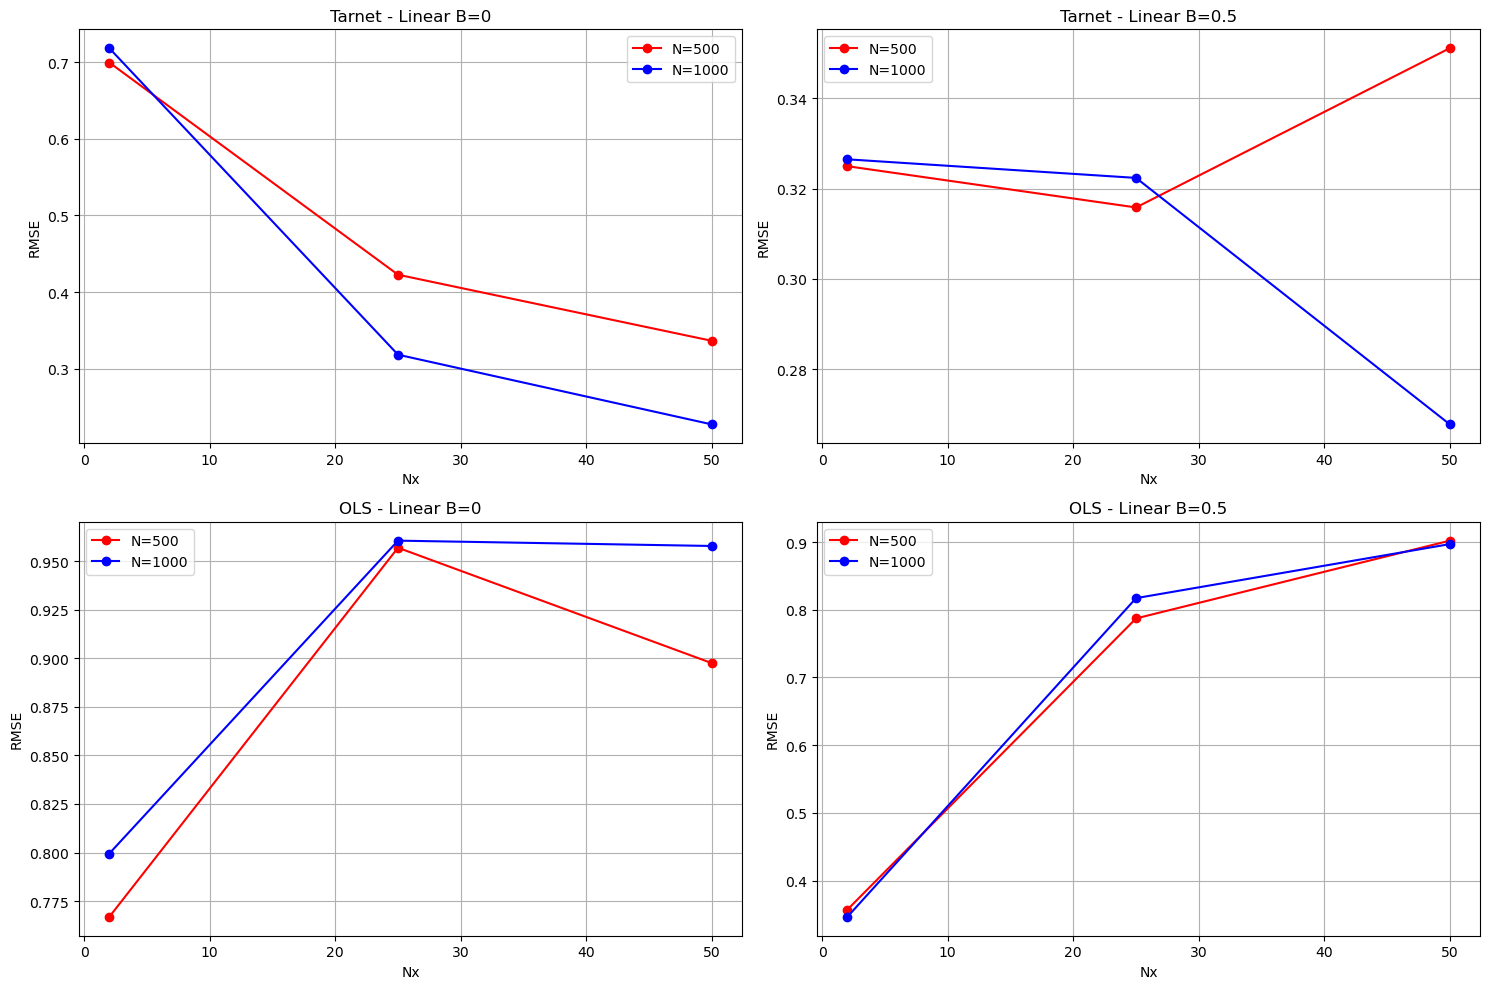

In [ ]:
import matplotlib.pyplot as plt

def plot_rmse_results(results_tarnet, results_ols):
    # Create a 2x2 subplot layout
    fig, axs = plt.subplots(2, 2, figsize=(15, 10))
    Nx_values = [2, 25, 50]

    # Plot RMSE results for tarnet (first row)
    for i, key in enumerate(["linear_0", "linear_0.5"]):
        ax = axs[0, i]
        ax.plot(Nx_values, results_tarnet[key][:3], marker='o', label='N=500', color='red')
        ax.plot(Nx_values, results_tarnet[key][3:], marker='o', label='N=1000', color='blue')

        ax.set_title(f'Tarnet - {key.replace("_", " B=").title()}')
        ax.set_xlabel("Nx")
        ax.set_ylabel("RMSE")
        ax.legend()
        ax.grid(True)

    # Plot RMSE results for OLS (second row)
    for i, key in enumerate(["linear_0", "linear_0.5"]):
        ax = axs[1, i]
        ax.plot(Nx_values, results_ols[key][:3], marker='o', label='N=500', color='red')
        ax.plot(Nx_values, results_ols[key][3:], marker='o', label='N=1000', color='blue')

        ax.set_title(f'OLS - {key.replace("_", " B=").title()}')
        ax.set_xlabel("Nx")
        ax.set_ylabel("RMSE")
        ax.legend()
        ax.grid(True)

    # Adjust layout
    plt.tight_layout()
    plt.show()

# Example usage
plot_rmse_results(formatted_results_tarnet, formatted_results_ols)


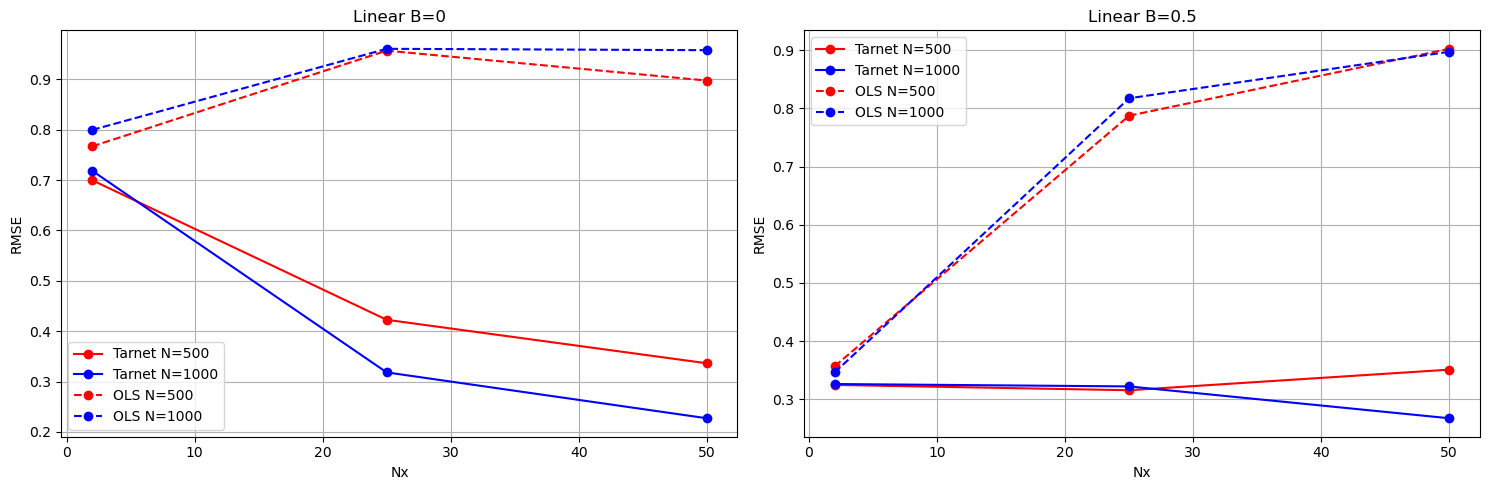

In [ ]:
##combine and comparasion
import matplotlib.pyplot as plt

def plot_rmse_results(results_tarnet, results_ols):
    # Create a 1x2 subplot layout
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    Nx_values = [2, 25, 50]

    # Plot RMSE results for tarnet and OLS in the same plot
    for i, key in enumerate(["linear_0", "linear_0.5"]):
        ax = axs[i]
        # Plot tarnet results
        ax.plot(Nx_values, results_tarnet[key][:3], marker='o', label='Tarnet N=500', color='red')
        ax.plot(Nx_values, results_tarnet[key][3:], marker='o', label='Tarnet N=1000', color='blue')

        # Plot OLS results with dotted lines
        ax.plot(Nx_values, results_ols[key][:3], marker='o', linestyle='--', label='OLS N=500', color='red')
        ax.plot(Nx_values, results_ols[key][3:], marker='o', linestyle='--', label='OLS N=1000', color='blue')

        ax.set_title(f'{key.replace("_", " B=").title()}')
        ax.set_xlabel("Nx")
        ax.set_ylabel("RMSE")
        ax.legend()
        ax.grid(True)

    # Adjust layout
    plt.tight_layout()
    plt.show()

# Example usage
plot_rmse_results(formatted_results_tarnet, formatted_results_ols)


## ATE and other metrics from TARNet

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np

def train_and_evaluate_tarnet_with_effects(datasets):
    """
    Train TARNet, calculate RMSE, ATE, ITE, and ITE standard deviation for each dataset.

    Parameters:
    datasets: dict
        Dictionary where keys are dataset names and values are tuples of (X, treatment, Y).

    Returns:
    dict
        A dictionary with metrics (RMSE, ATE, ITE Std Dev) for each dataset.
    """
    results = {}

    for dataset_name, data in datasets.items():
        print(f"Training on dataset: {dataset_name}")

        X, treatment, Y = data
        # Scale the input features and outcomes
        scaler_X = StandardScaler()
        scaler_Y = StandardScaler()

        X_scaled = scaler_X.fit_transform(X)
        data_Y = scaler_Y.fit(Y)
        Y = data_Y.transform(Y)
        #Y_scaled = scaler_Y.fit_transform(Y.reshape(-1, 1))

        input_dim = X.shape[1]

        # Train the TARNet model
        model = make_tarnet(input_dim, reg_l2=0.01)  # Replace with your TARNet implementation
        model.compile(optimizer='adam', loss=regression_loss)

        # Combine outcomes and treatment for training
        y_t = np.hstack([Y, treatment.reshape(-1, 1)])
        model.fit(X, y_t, epochs=10, batch_size=64, verbose=1)

        # Predict potential outcomes
        #predictions = model.predict(X)[:, :2]  # Columns: [y0_pred, y1_pred]
        predictions = model.predict(X)
        y0_pred = data_Y.inverse_transform(predictions[:, 0].reshape(-1, 1))
        y1_pred = data_Y.inverse_transform(predictions[:, 1].reshape(-1, 1))

        # Calculate metrics
        # ITE (Individual Treatment Effects)
        ite = y1_pred - y0_pred

        # ATE (Average Treatment Effect)
        ate = tf.reduce_mean(ite).numpy()

        # ITE Standard Deviation
        ite_std_dev = np.std(ite)

        # Store results
        results[dataset_name] = {
            #"RMSE": rmse,
            "ITE": ite,
            "ATE": ate,
            "ITE Standard Deviation": ite_std_dev
        }

    return results


In [ ]:
Results = train_and_evaluate_tarnet_with_effects(datasets)

Training on dataset: 500_2_0_l
Epoch 1/10
8/8 [==============================] - 1s 3ms/step - loss: 64.1056
Epoch 2/10
8/8 [==============================] - 0s 1ms/step - loss: 57.6081
Epoch 3/10
8/8 [==============================] - 0s 2ms/step - loss: 54.7477
Epoch 4/10
8/8 [==============================] - 0s 2ms/step - loss: 52.9835
Epoch 5/10
8/8 [==============================] - 0s 2ms/step - loss: 51.7544
Epoch 6/10
8/8 [==============================] - 0s 2ms/step - loss: 51.1948
Epoch 7/10
8/8 [==============================] - 0s 2ms/step - loss: 50.4881
Epoch 8/10
8/8 [==============================] - 0s 2ms/step - loss: 50.3540
Epoch 9/10
8/8 [==============================] - 0s 2ms/step - loss: 49.4398
Epoch 10/10
16/16 [==============================] - 0s 905us/step
Training on dataset: 500_2_05_l
Epoch 1/10
8/8 [==============================] - 1s 2ms/step - loss: 55.3930
Epoch 2/10
8/8 [==============================] - 0s 1ms/step - loss: 36.9192
Epoch 3/10
8

16/16 [==============================] - 0s 2ms/step - loss: 35.0170
Epoch 5/10
16/16 [==============================] - 0s 995us/step - loss: 32.5125
Epoch 6/10
16/16 [==============================] - 0s 2ms/step - loss: 31.9893
Epoch 7/10
16/16 [==============================] - 0s 2ms/step - loss: 30.5416
Epoch 8/10
16/16 [==============================] - 0s 814us/step - loss: 29.6382
Epoch 9/10
16/16 [==============================] - 0s 945us/step - loss: 28.6718
Epoch 10/10
32/32 [==============================] - 0s 1ms/step
Training on dataset: 1000_50_0_l
Epoch 1/10
16/16 [==============================] - 1s 1ms/step - loss: 73.5068
Epoch 2/10
16/16 [==============================] - 0s 732us/step - loss: 50.8554
Epoch 3/10
16/16 [==============================] - 0s 854us/step - loss: 43.1880
Epoch 4/10
16/16 [==============================] - 0s 852us/step - loss: 37.8297
Epoch 5/10
16/16 [==============================] - 0s 906us/step - loss: 34.6643
Epoch 6/10
16/16 [=

In [ ]:
Results

{'500_2_0_l': {'ITE': array([[-1.34195194e-01],
         [-1.08746663e-01],
         [-6.45263493e-02],
         [ 3.13012600e-02],
         [-6.97588503e-01],
         [ 1.38109863e-01],
         [ 1.22144364e-01],
         [ 1.56255698e+00],
         [ 1.98968112e-01],
         [ 4.44853544e-01],
         [ 1.28345942e+00],
         [-2.89556235e-01],
         [-2.85900563e-01],
         [-3.77067149e-01],
         [-8.10133219e-02],
         [-5.87342501e-01],
         [-5.91339588e-01],
         [ 6.18293822e-01],
         [-8.30071568e-02],
         [-7.86207318e-02],
         [ 1.06949949e+00],
         [-1.56991303e-01],
         [ 1.06102668e-01],
         [-2.30269551e-01],
         [ 1.03304982e-01],
         [ 1.13342404e-01],
         [-1.58847958e-01],
         [ 1.41642153e+00],
         [ 6.64417982e-01],
         [-3.10130715e-02],
         [ 1.68384802e+00],
         [-4.15692627e-01],
         [-6.81566417e-01],
         [-1.70547679e-01],
         [-8.15588474e-01],


In [ ]:
ate_values = {dataset: data['ATE'] for dataset, data in Results.items()}
ate_values

{'500_2_0_l': 0.0906093,
 '500_2_05_l': 5.0803576,
 '500_25_0_l': -0.40104276,
 '500_25_05_l': 6.9011602,
 '500_50_0_l': 5.8272676,
 '500_50_05_l': 6.6214433,
 '1000_2_0_l': -0.09857752,
 '1000_2_05_l': 4.9210978,
 '1000_25_0_l': 0.28130716,
 '1000_25_05_l': 6.54849,
 '1000_50_0_l': 12.33965,
 '1000_50_05_l': 7.1793394}

In [ ]:
formatted_results_tar_beta = {
    "linear_0": [],
    "linear_0.5": [],
}

for N in [500, 1000]:
    for Nx in [2, 25, 50]:
        formatted_results_tar_beta["linear_0"].append(ate_values[f"{N}_{Nx}_0_l"])
        formatted_results_tar_beta["linear_0.5"].append(ate_values[f"{N}_{Nx}_05_l"])
formatted_results_tar_beta

{'linear_0': [0.0906093,
  -0.40104276,
  5.8272676,
  -0.09857752,
  0.28130716,
  12.33965],
 'linear_0.5': [5.0803576,
  6.9011602,
  6.6214433,
  4.9210978,
  6.54849,
  7.1793394]}

In [ ]:
import numpy as np
import pandas as pd

# Data
beta_1_hat_values = formatted_results_tar_beta
# True beta_1 values
true_beta_1 = {'linear_0': 0, 'linear_0.5': 5}

# Initialize results
results = {}

# Calculate statistics for each group
for group, values in beta_1_hat_values.items():
    true_value = true_beta_1[group]
    bias = np.mean(values)-true_value
    variance = np.var(values)
    rmse = np.sqrt(np.mean((np.array(values) - true_value) ** 2))

    results[group] = {
        'Bias': bias,
        'Variance': variance,
        'RMSE': rmse
    }

# Convert to DataFrame for better visualization
results_df2 = pd.DataFrame(results).T
results_df2

,Bias,Variance,RMSE
linear_0,3.006536,22.041061,5.574972
linear_0.5,1.208648,0.773089,1.494630


In [ ]:
true_beta_1

{'linear_0': 0, 'linear_0.5': 5}

##Expectation, variance and RMSE of beta_1_hat over 2 kinds of datasets from OLS (preset ATE= 0 or 0.5)



In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from collections import defaultdict

def ols(X,Y,T):
    X = sm.add_constant(X)
    # Stack T to X matrix, so the first coefficient is B hat.
    XT = np.concatenate((T,X), axis=1)
    model = sm.OLS(Y, XT)
    results = model.fit()
    return results.params[0] #represent to beta_1_hat

def train_and_evaluate_ols_betahat(datasets):
    results = {}
    for dataset_name, data in datasets.items():
        print(f"Training on dataset: {dataset_name}")

        X, T, Y = data
        # Create an instance of StandardScaler
        scaler = StandardScaler()
        # Fit and transform the data
        X = scaler.fit_transform(X)
        Y = scaler.fit_transform(Y)
        results[dataset_name]= ols(X,Y,T)
    return results
train_and_evaluate_ols_betahat(datasets)

Training on dataset: 500_2_0_l
Training on dataset: 500_2_05_l
Training on dataset: 500_25_0_l
Training on dataset: 500_25_05_l
Training on dataset: 500_50_0_l
Training on dataset: 500_50_05_l
Training on dataset: 1000_2_0_l
Training on dataset: 1000_2_05_l
Training on dataset: 1000_25_0_l
Training on dataset: 1000_25_05_l
Training on dataset: 1000_50_0_l
Training on dataset: 1000_50_05_l


{'500_2_0_l': -0.08854193381828754,
 '500_2_05_l': 1.548873736495686,
 '500_25_0_l': 0.14564505104476488,
 '500_25_05_l': 0.5240305603940965,
 '500_50_0_l': -0.37183568296053565,
 '500_50_05_l': 0.3676064071978369,
 '1000_2_0_l': -0.007680285251947201,
 '1000_2_05_l': 1.5246525063059457,
 '1000_25_0_l': 0.08908571670485091,
 '1000_25_05_l': 0.5841505489382623,
 '1000_50_0_l': 0.0330198694546035,
 '1000_50_05_l': 0.18075405525922073}

In [ ]:
results = train_and_evaluate_ols_betahat(datasets)

Training on dataset: 500_2_0_l
Training on dataset: 500_2_05_l
Training on dataset: 500_25_0_l
Training on dataset: 500_25_05_l
Training on dataset: 500_50_0_l
Training on dataset: 500_50_05_l
Training on dataset: 1000_2_0_l
Training on dataset: 1000_2_05_l
Training on dataset: 1000_25_0_l
Training on dataset: 1000_25_05_l
Training on dataset: 1000_50_0_l
Training on dataset: 1000_50_05_l


In [ ]:
formatted_results_ols_beta = {
    "linear_0": [],
    "linear_0.5": [],
}

for N in [500, 1000]:
    for Nx in [2, 25, 50]:
        formatted_results_ols_beta["linear_0"].append(results[f"{N}_{Nx}_0_l"])
        formatted_results_ols_beta["linear_0.5"].append(results[f"{N}_{Nx}_05_l"])



In [ ]:
formatted_results_ols_beta

{'linear_0': [-0.08854193381828754,
  0.14564505104476488,
  -0.37183568296053565,
  -0.007680285251947201,
  0.08908571670485091,
  0.0330198694546035],
 'linear_0.5': [1.548873736495686,
  0.5240305603940965,
  0.3676064071978369,
  1.5246525063059457,
  0.5841505489382623,
  0.18075405525922073]}

In [ ]:
import numpy as np
import pandas as pd

# Data
beta_1_hat_values = formatted_results_ols_beta
# True beta_1 values
true_beta_1 = {'linear_0': 0, 'linear_0.5': 5}

# Initialize results
results = {}

# Calculate statistics for each group
for group, values in beta_1_hat_values.items():
    true_value = true_beta_1[group]
    bias = np.mean(values)- true_value
    variance = np.var(values)
    rmse = np.sqrt(np.mean((np.array(values) - true_value) ** 2))

    results[group] = {
        'Bias': bias,
        'Variance': variance,
        'RMSE': rmse
    }

# Convert to DataFrame for better visualization
results_df = pd.DataFrame(results).T
results_df

,Bias,Variance,RMSE
linear_0,-0.033385,0.028285,0.171464
linear_0.5,-4.211655,0.296383,4.246696


In [ ]:
## Here is my confusion: when there is no treatment effect, the bias and variance of ATE hat from OLS are both smaller than from tarnet?
# and when the real treatment effect is 0.5, the variance of ATE hat from OLS is smaller than from tarnet, which means there is higher variablity in tarnet estimator. And the bias from OLS and tarnet are rather similar.

In [ ]:
beta_1_hat_values

{'linear_0': [-0.08854193381828754,
  0.14564505104476488,
  -0.37183568296053565,
  -0.007680285251947201,
  0.08908571670485091,
  0.0330198694546035],
 'linear_0.5': [1.548873736495686,
  0.5240305603940965,
  0.3676064071978369,
  1.5246525063059457,
  0.5841505489382623,
  0.18075405525922073]}

In [ ]:
results_df2

,Bias,Variance,RMSE
linear_0,3.006536,22.041061,5.574972
linear_0.5,1.208648,0.773089,1.494630


# DeepIRTools verification

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro

def generate_datasets_linear():
    datasets = {}
    ns = [500, 1000]
    N_xs = [2, 25, 50]
    Bs = [0.0, 0.5]

    for n in ns:
        for N_x in N_xs:
            for B in Bs:
                Cov, treatment, Y = generate_linear_data(n, N_x, B)  # Y is the generated outcome from tarnet equation!
                # Latent loadings and variances
                latent_loadings = [0.8, 0.9, 0.7]
                variances = [1, 1, 1]
                # Generate observed variables X1, X2, X3
                X1 = latent_loadings[0] * Y + np.random.normal(0, np.sqrt(variances[0]), size=(n, 1))
                X2 = latent_loadings[1] * Y + np.random.normal(0, np.sqrt(variances[1]), size=(n, 1))
                X3 = latent_loadings[2] * Y + np.random.normal(0, np.sqrt(variances[2]), size=(n, 1))
                # Combine into a dataset
                dataset = pd.DataFrame(np.hstack((X1, X2, X3, Y)), columns=['X1', 'X2', 'X3', 'Y'])
                # Adjust key naming to replace 0.5 with 05
                B_adjusted = str(B).replace("0.5", "05").replace("0.0", "0")

                key = f"{n}_{N_x}_{B_adjusted}_l"
                datasets[key] = dataset
    return datasets

# Generate the datasets
datasets_linear = generate_datasets_linear()



## Simulation study is about verifying if we can recover the preset values of our methods.

In [ ]:
datasets_linear #this is only linear way!

{'500_2_0_l':            X1        X2        X3         Y
 0   -2.960000 -1.214113 -0.821711 -0.828857
 1    1.406151  0.327623  0.241114  0.903165
 2   -1.362080 -0.950975 -0.701832 -0.174598
 3    0.750563  3.839442  0.295128  2.711716
 4    1.767533  0.926844  1.288311  0.815008
 ..        ...       ...       ...       ...
 495  3.320518  0.738438  2.272978  2.542321
 496  0.801469 -0.455300  0.681038  0.328217
 497  1.623821  1.435721  1.262853  1.070234
 498 -1.830302  0.333002 -0.501507 -0.113267
 499 -0.011551 -0.461655 -0.249483  0.027554
 
 [500 rows x 4 columns],
 '500_2_05_l':            X1        X2        X3         Y
 0    0.059554 -1.024473 -1.949965 -0.716902
 1    1.042206  1.335806  0.994497  0.074761
 2    1.125962  1.444707  0.891102  0.651124
 3   -3.134430 -2.489401 -1.327942 -1.756604
 4    0.227651  3.613533  1.268544  1.940214
 ..        ...       ...       ...       ...
 495  1.352894 -1.697092 -0.984039 -0.252959
 496 -1.397021 -0.138369 -1.611475 -0.985702
 

In [ ]:
 # Save datasets to CSV files
for key, data in datasets_linear.items():
      data.to_csv(f'/content/{key}.csv', index=False)

OSError: Cannot save file into a non-existent directory: '\content'

In [ ]:
datasets_linear.items

<function dict.items>

In [ ]:
!pip install deepirtools

     -------------------------------------- 431.5/431.5 kB 3.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import deepirtools
from deepirtools import IWAVE
from sklearn.preprocessing import StandardScaler
import torch

# Assuming `deepIRTools` provides a fit function similar to this

def fit_model_deepirtools(file_path):
    deepirtools.manual_seed(123)
    # Step 1: Read the dataset CSV file into a data frame
    df = pd.read_csv(file_path)
    data = df[['X1', 'X2', 'X3']]

    # Step 2: Standardize the values of the three observed variables
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    # Convert the scaled data back to a DataFrame
    data = pd.DataFrame(scaled_data, columns=data.columns)

    # Step 3: Convert the data into a torch.tensor
    numpy_array = data.to_numpy()
    data_tensor = torch.tensor(numpy_array, dtype=torch.float32)
    #data_tensor = torch.tensor(data[['X1', 'X2', 'X3']].values, dtype=torch.float32).to('cuda')

    # Step 4: Fit the IWAVE model
    model = IWAVE(
        model_type = "normal",
        latent_size = 1,  # Number of latent variables is 1
        n_items = 3,
        Q = torch.block_diag(*[torch.ones([3, 1])] * 1),  # Is it correct? Yes, for this case.
        device = 'cuda'
    )
    model.fit(data_tensor, iw_samples = 5000)

    # Step 5: Get the estimated loadings
    estimated_loadings = model.loadings

    return estimated_loadings

In [ ]:
# Function to compare loadings and calculate metrics
def compare_loadings(true_loadings, estimated_loadings):
    true_loadings = np.array(true_loadings, dtype=np.float32)
    estimated_loadings = np.array(estimated_loadings, dtype=np.float32)
    mse = mean_squared_error(true_loadings, estimated_loadings)
    rmse = np.sqrt(mse)
    return rmse

# Main function to simulate data, fit the model, and compare loadings
def calculate_RMSE():
    latent_loadings = [0.8, 0.9, 0.7]
    variances = [1, 1, 1]



    # Fit models and compare loadings
    results = {}
    for key, data in datasets.items():
        estimated_loadings = fit_model_deepirtools(f'/content/{key}.csv')
        rmse_loadings = compare_loadings(latent_loadings, estimated_loadings)
        results[key] = {
            'RMSE': rmse_loadings
        }
        #visualize_comparison(latent_loadings, estimated_loadings, title=f'{key} Loadings Comparison')
    return results

In [ ]:
results = calculate_RMSE()

FileNotFoundError: [Errno 2] No such file or directory: '/content/500_2_0_l.csv'

In [ ]:
results

{'linear_0': {'Bias': -0.03338454413775851,
  'Variance': 0.028285387803048966,
  'RMSE': 0.17146403585106385},
 'linear_0.5': {'Bias': -4.211655364234826,
  'Variance': 0.2963829865516889,
  'RMSE': 4.246695644102561}}

In [ ]:
formatted_results_deepirtools = {
    "linear_0": [],
    "linear_0.5": [],
}

for N in [500, 1000]:
    for Nx in [2, 25, 50]:
        formatted_results_deepirtools["linear_0"].append(results[f"{N}_{Nx}_0_l"])
        formatted_results_deepirtools["linear_0.5"].append(results[f"{N}_{Nx}_05_l"])

KeyError: '500_2_0_l'

In [ ]:
formatted_results_deepirtools


{'linear_0': [{'RMSE': 0.09347717},
  {'RMSE': 0.14640793},
  {'RMSE': 0.17758428},
  {'RMSE': 0.11058745},
  {'RMSE': 0.15852034},
  {'RMSE': 0.17780213}],
 'linear_0.5': [{'RMSE': 0.055718035},
  {'RMSE': 0.1523272},
  {'RMSE': 0.19006266},
  {'RMSE': 0.06004663},
  {'RMSE': 0.14727175},
  {'RMSE': 0.18349406}]}

In [ ]:
original_dict = formatted_results_deepirtools

# Transform the original dictionary to the desired structure
formatted_results_deepirtools= {
    key: [entry['RMSE'] for entry in value]
    for key, value in original_dict.items()
}




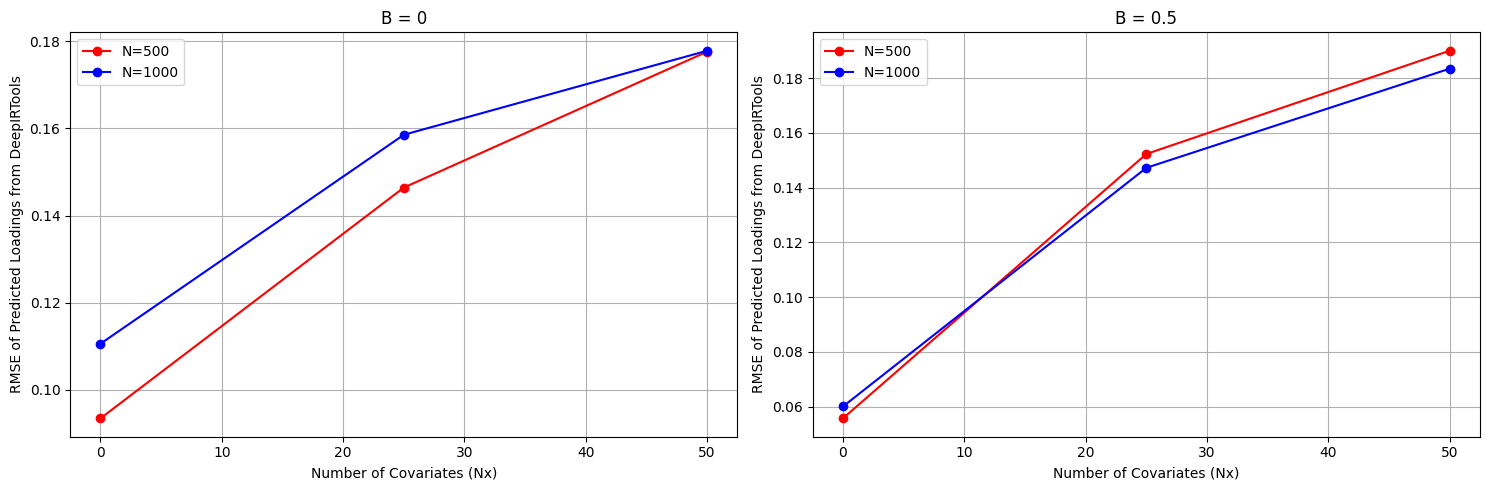

In [ ]:
import matplotlib.pyplot as plt

def plot_rmse_results(results):
    # Ensure results is a dictionary
    if not isinstance(results, dict):
        raise TypeError("The 'results' parameter should be a dictionary with keys like 'linear_0' and values as lists.")

    # Create a 1x2 subplot layout
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    Nx_values = [0, 25, 50]

    # Plot RMSE of predicted loadings for beta=0 and beta=0.5
    for i, key in enumerate(["linear_0", "linear_0.5"]):
        if key not in results or not isinstance(results[key], (list, tuple)):
            raise ValueError(f"Expected 'results' to have key '{key}' with a list or tuple of RMSE values.")

        ax = axs[i]
        # Plot RMSE results for N=500 and N=1000
        ax.plot(Nx_values, results[key][:3], marker='o', label='N=500', color='red')
        ax.plot(Nx_values, results[key][3:], marker='o', label='N=1000', color='blue')

        ax.set_title(f'B = {key.split("_")[1]}')
        ax.set_xlabel("Number of Covariates (Nx)")
        ax.set_ylabel("RMSE of Predicted Loadings from DeepIRTools")
        ax.legend()
        ax.grid(True)

    # Adjust layout
    plt.tight_layout()
    plt.show()


plot_rmse_results(formatted_results_deepirtools)

##overall, RMSE looks very small.

In [ ]:
##traditional CFA
!pip install semopy pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 10.1 MB/s eta 0:00:00
  Created wheel for semopy: filename=semopy-2.3.11-py3-none-any.whl size=1659681 sha256=20ccee3fc5f7067c6c1b4df2360ca16d33343661d499302a68a2695a37ca7fce
  Stored in directory: /root/.cache/pip/wheels/53/ec/0d/0b294c02d8c4e9e80afea58839f2c1b4706770594bc99ec045
Successfully built semopy


In [ ]:
import pandas as pd
from semopy import Model

def process_CFA(file_path):
    """
    Process a CSV file using Confirmatory Factor Analysis (CFA).

    Args:
        file_path (str): Path to the CSV file to process.

    Returns:
        pd.DataFrame: DataFrame containing the estimated loadings and model results.
    """
    try:
        # Read the CSV file
        df = pd.read_csv(file_path)

        # Ensure all data is numeric (convert non-numeric columns to NaN)
        df = df.apply(pd.to_numeric, errors='coerce')

        # Drop rows with any NaN values to ensure clean data for analysis
        df = df.dropna()

        # Ensure the required columns are present
        required_columns = ['X1', 'X2', 'X3', 'Y']
        if not all(col in df.columns for col in required_columns):
            raise ValueError(f"Missing one or more required columns: {required_columns}")

        # Extract relevant columns for CFA
        df = df[required_columns]

        # Define the CFA model description
        model_desc = """
        Y =~ X1 + X2 + X3
        """

        # Create and fit the CFA model
        model = Model(model_desc)
        model.fit(df)

        # Inspect and return the model results
        estimates = model.inspect()
        return estimates

    except Exception as e:
        print(f"Error processing CFA: {e}")
        return None


In [ ]:
import os
from google.colab import drive
def process_multiple_csv(files_list):
    """
    Processes multiple CSV files one by one using CFA.

    Args:
        files_list (list): List of file paths to process.

    Returns:
        dict: A dictionary where keys are file names and values are the CFA results.
    """
    results = {}
    for file_path in files_list:
        print(f"Processing file: {file_path}")
        try:
            # Call the process_CFA function for each file
            result = process_CFA(file_path)
            results[file_path] = result
            print(f"Successfully processed: {file_path}")
        except Exception as e:
            print(f"Error processing {file_path}: {e}")
    return results


# Mount Google Drive if your files are stored there
from google.colab import drive
drive.mount('/content/drive')

# Define the directory to search for CSV files (adjust as needed)
directory = "/content"
csv_files = [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('l.csv')]

# Process all files
cfa_results = process_multiple_csv(csv_files)

# Optionally, save or inspect the results
for file, result in cfa_results.items():
    print(f"Results for {file}:")
    print(result)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processing file: /content/500_50_05_l.csv
Successfully processed: /content/500_50_05_l.csv
Processing file: /content/1000_2_0_l.csv
Successfully processed: /content/1000_2_0_l.csv
Processing file: /content/1000_2_05_l.csv
Successfully processed: /content/1000_2_05_l.csv
Processing file: /content/500_2_0_l.csv
Successfully processed: /content/500_2_0_l.csv
Processing file: /content/500_50_0_l.csv
Successfully processed: /content/500_50_0_l.csv
Processing file: /content/500_2_05_l.csv
Successfully processed: /content/500_2_05_l.csv
Processing file: /content/1000_25_05_l.csv
Successfully processed: /content/1000_25_05_l.csv
Processing file: /content/1000_25_0_l.csv
Successfully processed: /content/1000_25_0_l.csv
Processing file: /content/500_25_05_l.csv
Successfully processed: /content/500_25_05_l.csv
Processing file: /content/500_25_0_l.csv
Successfully proces

In [ ]:
###How to save the estimate column, the first 3 numbers as loadings?
for file, result in cfa_results.items():
    estimated = result['Estimate'].head(3).tolist()
    print(estimated)

[1.0, 1.1169048978861809, 0.8901556053654065]
[1.0, 1.1178315393281655, 0.8330300565287402]
[1.0, 1.110733843042949, 0.8413503993733973]
[1.0, 1.2576196272642004, 0.8653442301301183]
[1.0, 1.1426624282778606, 0.8903292899398388]
[1.0, 1.2364335647522504, 0.8877855887738273]
[1.0, 1.0859522841913323, 0.8533348999100426]
[1.0, 1.1421282371946055, 0.8803687967094701]
[1.0, 1.1275142824970041, 0.9161056075771402]
[1.0, 1.110789247273372, 0.8912078556389869]
[1.0, 1.1407406242987974, 0.8832353607614238]
[1.0, 1.1350672524110141, 0.8891884798184981]


In [ ]:
import numpy as np

def calculate_rmse(true_values, estimated_values):
    """
    Calculate the RMSE between true values and estimated values.
    """
    errors = np.array(true_values) - np.array(estimated_values)
    mse = np.mean(errors ** 2)
    return np.sqrt(mse)

def calculate_RMSE_CFA():
    # True latent loadings
    latent_loadings = [0.8, 0.9, 0.7]

    # Dictionary to store RMSE results
    results = {}

    # Loop through the CFA results
    for file, result in cfa_results.items():
        # Get the first three estimated values
        estimated = result['Estimate'].head(3).tolist()
        print(f"File: {file}, Estimated Loadings: {estimated}")

        # Calculate RMSE for this file
        rmse_loadings = calculate_rmse(latent_loadings, estimated)

        # Store RMSE in the results dictionary
        results[file] = {
            "RMSE_Loadings": rmse_loadings
        }

    return results


In [ ]:
results = calculate_RMSE_CFA()

File: /content/500_50_05_l.csv, Estimated Loadings: [1.0, 1.1169048978861809, 0.8901556053654065]
File: /content/1000_2_0_l.csv, Estimated Loadings: [1.0, 1.1178315393281655, 0.8330300565287402]
File: /content/1000_2_05_l.csv, Estimated Loadings: [1.0, 1.110733843042949, 0.8413503993733973]
File: /content/500_2_0_l.csv, Estimated Loadings: [1.0, 1.2576196272642004, 0.8653442301301183]
File: /content/500_50_0_l.csv, Estimated Loadings: [1.0, 1.1426624282778606, 0.8903292899398388]
File: /content/500_2_05_l.csv, Estimated Loadings: [1.0, 1.2364335647522504, 0.8877855887738273]
File: /content/1000_25_05_l.csv, Estimated Loadings: [1.0, 1.0859522841913323, 0.8533348999100426]
File: /content/1000_25_0_l.csv, Estimated Loadings: [1.0, 1.1421282371946055, 0.8803687967094701]
File: /content/500_25_05_l.csv, Estimated Loadings: [1.0, 1.1275142824970041, 0.9161056075771402]
File: /content/500_25_0_l.csv, Estimated Loadings: [1.0, 1.110789247273372, 0.8912078556389869]
File: /content/1000_50_05_l

In [ ]:
results

{'/content/500_50_05_l.csv': {'RMSE_Loadings': 0.20265478773758652},
 '/content/1000_2_0_l.csv': {'RMSE_Loadings': 0.18721429385076155},
 '/content/1000_2_05_l.csv': {'RMSE_Loadings': 0.18653747434646042},
 '/content/500_2_0_l.csv': {'RMSE_Loadings': 0.25510162173919837},
 '/content/500_50_0_l.csv': {'RMSE_Loadings': 0.21221867079870788},
 '/content/500_2_05_l.csv': {'RMSE_Loadings': 0.2506331787314146},
 '/content/1000_25_05_l.csv': {'RMSE_Loadings': 0.1808220520533901},
 '/content/1000_25_0_l.csv': {'RMSE_Loadings': 0.20909247242419585},
 '/content/500_25_05_l.csv': {'RMSE_Loadings': 0.2148366684766294},
 '/content/500_25_0_l.csv': {'RMSE_Loadings': 0.2008254223815089},
 '/content/1000_50_05_l.csv': {'RMSE_Loadings': 0.20938898858436011},
 '/content/1000_50_0_l.csv': {'RMSE_Loadings': 0.20900470014818462}}

In [ ]:
def extract_treatment_effect(file_name):
    """
    Extracts the true treatment effect from the file name.
    Assumes the treatment effect is the third underscore-separated value in the file name.
    """
    parts = file_name.split('_')
    # Extract the treatment effect (e.g., 0 or 0.5)
    effect = parts[2]
    if effect.endswith('.csv') or effect.endswith('.l.csv'):
        effect = effect.split('.')[0]
      # Handle the specific case of '05' as 0.5
    if effect == '05':
        return 0.5
    return float(effect)

def organize_rmse_by_treatment_effect(rmse_results):
    """
    Organizes RMSE values into two groups based on true treatment effect (0 or 0.5),
    using keys 'linear_0' and 'linear_0.5'.
    """
    grouped_rmse = {"linear_0": [], "linear_0.5": []}

    for file_name, metrics in rmse_results.items():
        treatment_effect = extract_treatment_effect(file_name)
        rmse = metrics['RMSE_Loadings']

        if treatment_effect == 0.0:
            grouped_rmse["linear_0"].append(rmse)
        elif treatment_effect == 0.5:
            grouped_rmse["linear_0.5"].append(rmse)
        else:
            print(f"Warning: Unexpected treatment effect {treatment_effect} in file {file_name}")

    return grouped_rmse
grouped_results = organize_rmse_by_treatment_effect(results)
grouped_results

{'linear_0': [0.18721429385076155,
  0.25510162173919837,
  0.21221867079870788,
  0.20909247242419585,
  0.2008254223815089,
  0.20900470014818462],
 'linear_0.5': [0.20265478773758652,
  0.18653747434646042,
  0.2506331787314146,
  0.1808220520533901,
  0.2148366684766294,
  0.20938898858436011]}

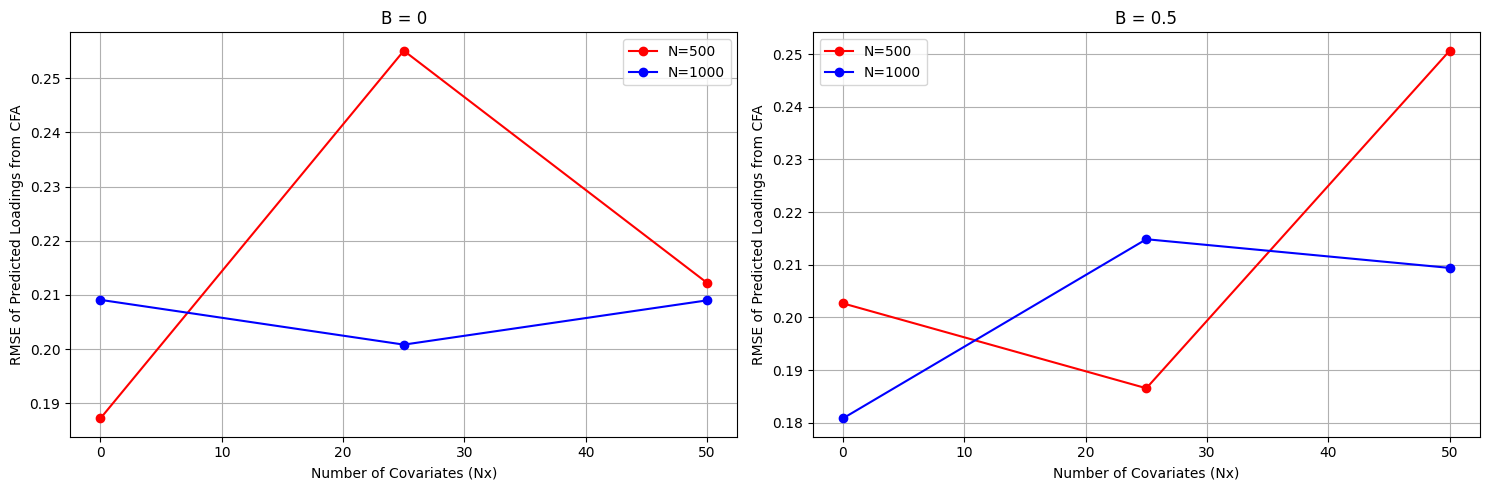

In [ ]:
##illustration
import matplotlib.pyplot as plt

def plot_rmse_results(results):
    # Ensure results is a dictionary
    if not isinstance(results, dict):
        raise TypeError("The 'results' parameter should be a dictionary with keys like 'linear_0' and values as lists.")

    # Create a 1x2 subplot layout
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    Nx_values = [0, 25, 50]

    # Plot RMSE of predicted loadings for beta=0 and beta=0.5
    for i, key in enumerate(["linear_0", "linear_0.5"]):
        if key not in results or not isinstance(results[key], (list, tuple)):
            raise ValueError(f"Expected 'results' to have key '{key}' with a list or tuple of RMSE values.")

        ax = axs[i]
        # Plot RMSE results for N=500 and N=1000
        ax.plot(Nx_values, results[key][:3], marker='o', label='N=500', color='red')
        ax.plot(Nx_values, results[key][3:], marker='o', label='N=1000', color='blue')

        ax.set_title(f'B = {key.split("_")[1]}')
        ax.set_xlabel("Number of Covariates (Nx)")
        ax.set_ylabel("RMSE of Predicted Loadings from CFA")
        ax.legend()
        ax.grid(True)

    # Adjust layout
    plt.tight_layout()
    plt.show()


plot_rmse_results(grouped_results)

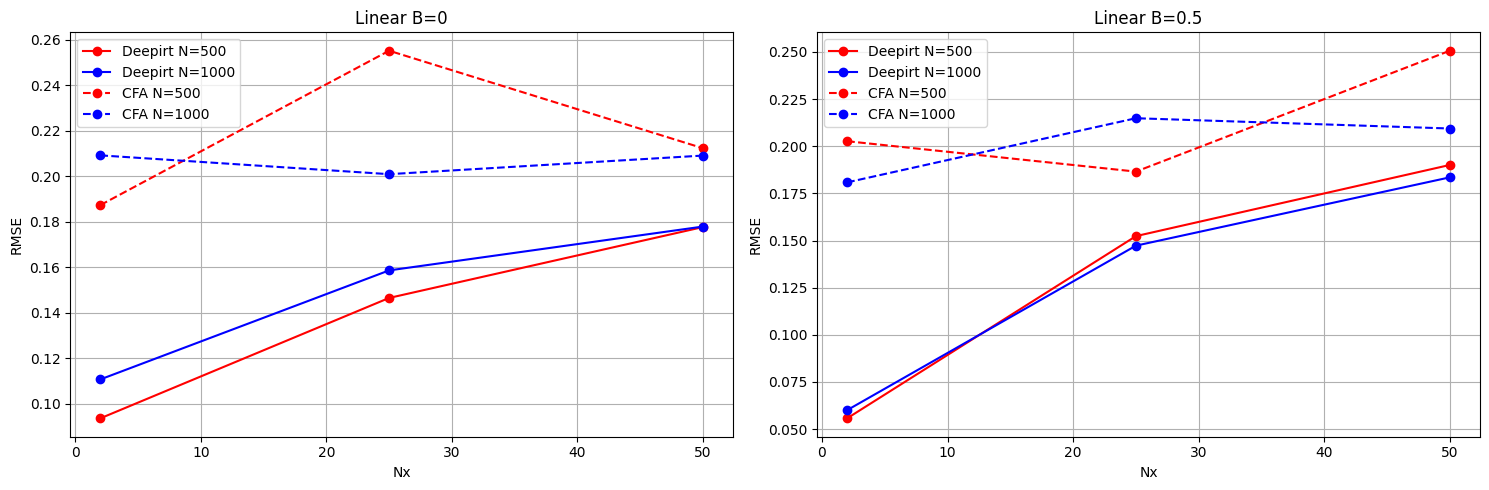

In [ ]:
##combine and comparasion
import matplotlib.pyplot as plt

def plot_rmse_results(results_tarnet, results_ols):
    # Create a 1x2 subplot layout
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    Nx_values = [2, 25, 50]

    # Plot RMSE results for tarnet and OLS in the same plot
    for i, key in enumerate(["linear_0", "linear_0.5"]):
        ax = axs[i]
        # Plot DeepIRTools results
        ax.plot(Nx_values, results_tarnet[key][:3], marker='o', label='Deepirt N=500', color='red')
        ax.plot(Nx_values, results_tarnet[key][3:], marker='o', label='Deepirt N=1000', color='blue')

        # Plot CFA results with dotted lines
        ax.plot(Nx_values, results_ols[key][:3], marker='o', linestyle='--', label='CFA N=500', color='red')
        ax.plot(Nx_values, results_ols[key][3:], marker='o', linestyle='--', label='CFA N=1000', color='blue')

        ax.set_title(f'{key.replace("_", " B=").title()}')
        ax.set_xlabel("Nx")
        ax.set_ylabel("RMSE")
        ax.legend()
        ax.grid(True)

    # Adjust layout
    plt.tight_layout()
    plt.show()

# Example usage
plot_rmse_results(formatted_results_deepirtools, grouped_results)

# Experiments on semopy

In [ ]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# Number of samples
n_samples = 500

# Latent variables
Factor1 = np.random.normal(size=n_samples)
Factor2 = np.random.normal(size=n_samples)

# Observed variables influenced by latent factors
y1 = 0.8 * Factor1 + np.random.normal(scale=0.5, size=n_samples)
y2 = 0.6 * Factor1 + np.random.normal(scale=0.5, size=n_samples)
y3 = 0.7 * Factor1 + np.random.normal(scale=0.5, size=n_samples)
y4 = 0.9 * Factor2 + np.random.normal(scale=0.5, size=n_samples)
y5 = 0.5 * Factor2 + np.random.normal(scale=0.5, size=n_samples)
y6 = 0.6 * Factor2 + np.random.normal(scale=0.5, size=n_samples)

# Combine into a DataFrame
data = pd.DataFrame({
    'y1': y1,
    'y2': y2,
    'y3': y3,
    'y4': y4,
    'y5': y5,
    'y6': y6
})


In [ ]:
from semopy import Model

# Define the model
model_desc = """
Factor1 =~ y1 + y2 + y3
Factor2 =~ y4 + y5 + y6
Factor1 ~~ Factor2
"""
model = Model(model_desc)
# Fit the model
model.fit(data)


SolverResult(fun=0.017739320536221292, success=True, n_it=23, x=array([ 0.79804072,  0.86844619,  0.51744917,  0.60839687, -0.03050123,
        0.58063808,  0.83652879,  0.24325822,  0.25481041,  0.25720636,
        0.23491625,  0.29075438,  0.26112345]), message='Optimization terminated successfully', name_method='SLSQP', name_obj='MLW')

In [ ]:
# Inspect the parameter estimates
estimates = model.inspect()

In [ ]:
estimates

,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,y1,~,Factor1,1.000000,-,-,-
1,y2,~,Factor1,0.798041,0.047322,16.863946,0.0
2,y3,~,Factor1,0.868446,0.050622,17.155438,0.0
3,y4,~,Factor2,1.000000,-,-,-
4,y5,~,Factor2,0.517449,0.039459,13.113619,0.0
5,y6,~,Factor2,0.608397,0.043701,13.921828,0.0
6,Factor1,~~,Factor2,-0.030501,0.036847,-0.82777,0.407801
7,Factor1,~~,Factor1,0.580638,0.055779,10.409593,0.0
8,Factor2,~~,Factor2,0.836529,0.082093,10.18999,0.0
9,y1,~~,y1,0.243258,0.029487,8.249654,0.0


In [ ]:
print(estimates['Estimate'].head(3).tolist())

[1.0, 0.7980407161900134, 0.868446191092887]
